<a href="https://colab.research.google.com/github/bulah16/C7-Project/blob/main/Transfer_Learning_Surface_Defect_MBulah.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Industrial Surface Defect Classification using Transfer Learning

**Assignment:** Industrial Surface Defect Classification using Transfer Learning
**Submitted by:** M Bulah (Beulah M)
**Notebook:** `Transfer_Learning_Surface_Defect_MBulah.ipynb`
**Framework:** PyTorch + torchvision &nbsp;|&nbsp; **Backbone:** MobileNetV2 (ImageNet weights)**Github link:** https://github.com/bulah16/C7-Project

## Objective

The aim of this assignment is to automatically classify surface defects in steel materials using real-world industrial image data and a transfer learning approach.

Surface defects such as cracks, scratches, inclusions, and pits commonly occur during manufacturing processes and can significantly affect product quality. Manual inspection of these defects is time-consuming, inconsistent, and difficult to scale.

In this assignment, we use a dataset containing steel surface images belonging to six different defect categories:
- Crazing  
- Inclusion  
- Patches  
- Pitted Surface  
- Rolled-in Scale  
- Scratches  

All defect types originate from the same manufacturing domain, and learning from all categories together allows the model to capture shared texture and structural patterns present across industrial surfaces.

The problem statement for this assignment is:

> **Given a steel surface image, predict the type of surface defect present in the image using a pretrained convolutional neural network.**

To solve this problem efficiently, we apply **transfer learning** by reusing a pretrained `MobileNetV2` model as a feature extractor and training only a lightweight classification head. This demonstrates how deep learning models can be adapted to real industrial use cases using limited data and computational resources.

## Business Value

In manufacturing industries such as steel, automotive, and heavy engineering, surface defects can directly impact product quality, safety, customer satisfaction, production cost, and rework rates.

Traditional inspection methods rely heavily on human inspectors, which introduces inconsistency in defect detection. Manual inspection also comes with high operational costs and scalability limitations.

By applying transfer learning, organisations can:
- Reuse pretrained visual intelligence instead of training models from scratch  
- Reduce development and training time  
- Achieve reliable defect detection even with smaller datasets  
- Deploy lightweight models suitable for real-time or edge-based inspection systems

## Dataset Description

This assignment uses the **NEU Surface Defect Dataset**, a real-world industrial dataset commonly used in manufacturing research and automated inspection systems.

### Dataset Characteristics:
- Images represent steel surface textures captured under industrial conditions  
- Each image belongs to one of six defect categories:
  - Crazing  
  - Inclusion  
  - Patches  
  - Pitted Surface  
  - Rolled-in Scale  
  - Scratches  
- Images are originally grayscale
- The dataset is reasonably balanced across classes  


#### Why this dataset?

- It represents a real industrial computer vision problem
- Defect patterns are texture-based, making it ideal for demonstrating transfer learning  
- The dataset size is moderate, encouraging the use of **partial transfer learning** rather than full model retraining  

## Flow Diagram

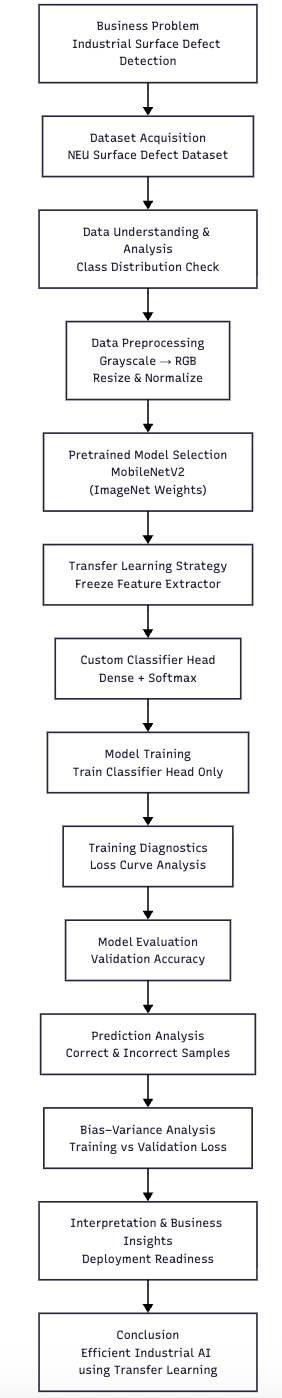

**Note:** You are free to choose any pre-trained model from the available ones. However, the architecture we suggest for this assignment is `MobileNetV2` with "ImageNet" weights.

The choice of libraries, frameworks, and backbones for this assignment are up to you. Before starting this assignment, please ensure that your environment meets the following requirements.


**Software Requirements**

- *Python version*: > Python3.11  
- *Execution environment*: Jupyter Notebook / JupyterLab / VS Code Notebook  
- *Operating system*: macOS, Linux, or Windows  


**Hardware Requirements**
- A GPU-powered training would be optimal, and would require installation of proper libraries and CUDA
- However, CPU-only execution might also be sufficient, and would work without CUDA

### Assumptions

1. **Framework.** PyTorch and torchvision are used throughout (the notebook allows either PyTorch or TensorFlow).
2. **Dataset location and layout.** The NEU Surface Defect dataset sits in a folder called `NEU-DET` next to this notebook, in the standard layout `NEU-DET/train/images/<class>/` and `NEU-DET/validation/images/<class>/`. If your copy has no `images` level (`NEU-DET/train/<class>/`), the loader detects that automatically. Change `DATA_ROOT` in Section 1.1.1 if it lives elsewhere.
3. **Split.** The existing train/validation split is used as provided: 240 training and 60 validation images per class (1,440 / 360 in total). No separate test set exists, so the validation set doubles as the held-out evaluation set and is never used to update weights.
4. **Pretrained weights.** The backbone is MobileNetV2 with ImageNet-1k weights. The code first requests torchvision's official `IMAGENET1K_V1` weights. If that download is blocked (as it was in the environment where this notebook was executed), it falls back to a local copy of ImageNet-pretrained MobileNetV2 weights (`mobilenet_v2_imagenet_local.pth`, same architecture, 72.2% ImageNet top-1, from the public `d-li14/mobilenetv2.pytorch` release), mapped one-to-one onto torchvision's layers. Either source gives a genuine ImageNet-pretrained feature extractor.
5. **Input format.** Images are treated as grayscale, replicated to 3 channels, resized to 224 x 224 (the resolution MobileNetV2 was pretrained at), and normalised with ImageNet mean and standard deviation.
6. **Augmentation.** Only light, label-preserving augmentation is applied to training images (random horizontal and vertical flips). Steel-surface defects have no natural "up" or "left", so flips do not change the class. Validation images are never augmented.
7. **Freezing strategy.** The entire convolutional feature extractor (`model.features`) is frozen and kept in evaluation mode, so its BatchNorm statistics stay at their ImageNet values. Only the new classification head is trained (partial transfer learning, as the assignment specifies).
8. **Hardware.** The notebook runs on CPU in a reasonable time; it uses a GPU automatically if one is available. Random seeds are fixed for reproducibility, but exact numbers can still vary slightly across hardware and library versions.

### Import Necessary libraries

In [ ]:
# Import Required Libraries

import os
import copy
import random
import time
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import torchvision
from torchvision import datasets, models, transforms

from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, f1_score)

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Keep CPU runs responsive
torch.set_num_threads(max(1, os.cpu_count() or 1))

# Folder for saved figures (also used in the written report)
FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.3})

print(f"PyTorch {torch.__version__} | torchvision {torchvision.__version__}")

PyTorch 2.14.1+cu130 | torchvision 0.29.1+cu130


## 1. Data Loading and Preparation

<font color=red>[10 marks]</font>

In any machine learning workflow, understanding and preparing the data correctly is a critical first step. Before building a deep learning model, it is important
to examine how the dataset is structured, how labels are assigned, and how images are preprocessed for training.

This section includes the following steps:
- Understanding the dataset organisation
- Verifying class labels and distributions
- Applying appropriate image transformations for transfer learning
- Development of train loader and validation loader

### 1.1 Dataset Understanding and Structure

<font color=red>[4 marks]</font>

The NEU Surface Defect Dataset consists of real-world grayscale images collected from steel manufacturing processes. Each image belongs to one of six surface defect categories.

The dataset is already split into **training** and **validation** sets, and images are organised into class-specific folders. This structure allows us to use PyTorch’s `ImageFolder` utility, which automatically assigns labels based on directory names.

The same directory-based structure is also compatible with TensorFlow, allowing the dataset to be loaded directly using `tf.keras.utils.image_dataset_from_directory`, which infers class labels from folder names in a similar manner.



Before proceeding, we load the dataset and verify:
- Number of images in training and validation sets
- Mapping between class names and numeric labels

#### **1.1.1** Load Images and Labels  <font color=red>[3 marks]</font>

Load the training and validation datasets and check the number of images and the number of categories present

In [ ]:
# Load training and validation images + labels


# Dataset statistics

DATA_ROOT = "NEU-DET"   # change if the dataset lives elsewhere (see Assumption 2)


def split_dir(split):
    """Return the folder that directly contains the class sub-folders."""
    base = os.path.join(DATA_ROOT, split)
    images = os.path.join(base, "images")
    return images if os.path.isdir(images) else base


TRAIN_DIR = split_dir("train")
VAL_DIR = split_dir("validation")

# A first, transform-free load: used only to inspect the raw data.
raw_train = datasets.ImageFolder(TRAIN_DIR)
raw_val = datasets.ImageFolder(VAL_DIR)

assert raw_train.class_to_idx == raw_val.class_to_idx, "Train/val class folders differ"
CLASS_NAMES = raw_train.classes
NUM_CLASSES = len(CLASS_NAMES)

# Dataset statistics
print(f"Training images   : {len(raw_train)}")
print(f"Validation images : {len(raw_val)}")
print(f"Number of classes : {NUM_CLASSES}\n")
print("Class -> label mapping:")
for name, idx in raw_train.class_to_idx.items():
    print(f"  {idx}: {name}")

sample_img, sample_label = raw_train[0]
print(f"\nExample image: size={sample_img.size}, mode={sample_img.mode}, "
      f"label={sample_label} ({CLASS_NAMES[sample_label]})")

Training images   : 1440
Validation images : 360
Number of classes : 6

Class -> label mapping:
  0: crazing
  1: inclusion
  2: patches
  3: pitted_surface
  4: rolled-in_scale
  5: scratches

Example image: size=(200, 200), mode=RGB, label=0 (crazing)


Here, the image loader automatically assigns numeric labels based on folder names. For example, all images inside the "crazing" folder receive the same label.

This approach reduces manual labeling effort and ensures consistency between directory structure and class definitions.

#### **1.1.2** Check and Visualise Class Distribution <font color=red>[1 mark]</font>

In [ ]:
# Dataset Class Distribution

train_counts = Counter(raw_train.targets)
val_counts = Counter(raw_val.targets)

dist_df = pd.DataFrame({
    "class": CLASS_NAMES,
    "train": [train_counts[i] for i in range(NUM_CLASSES)],
    "validation": [val_counts[i] for i in range(NUM_CLASSES)],
})
dist_df["total"] = dist_df["train"] + dist_df["validation"]
dist_df["train_share_%"] = (100 * dist_df["train"] / dist_df["train"].sum()).round(1)
dist_df

,class,train,validation,total,train_share_%
0,crazing,240,60,300,16.7
1,inclusion,240,60,300,16.7
2,patches,240,60,300,16.7
3,pitted_surface,240,60,300,16.7
4,rolled-in_scale,240,60,300,16.7
5,scratches,240,60,300,16.7


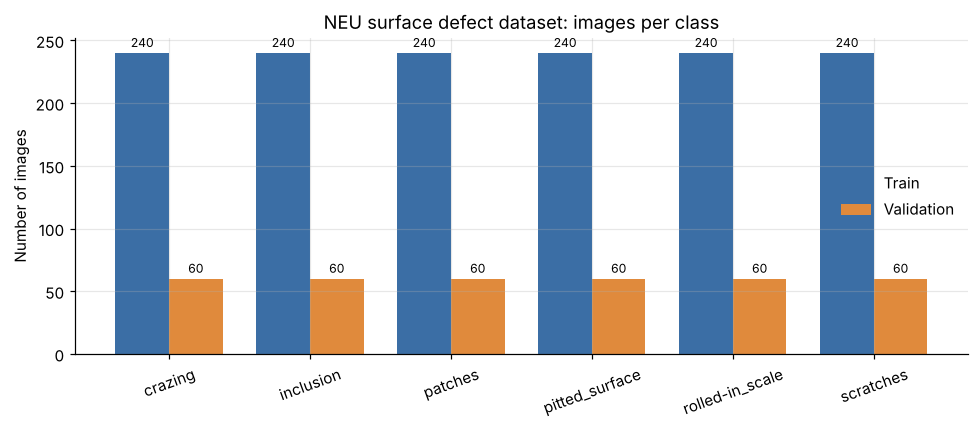

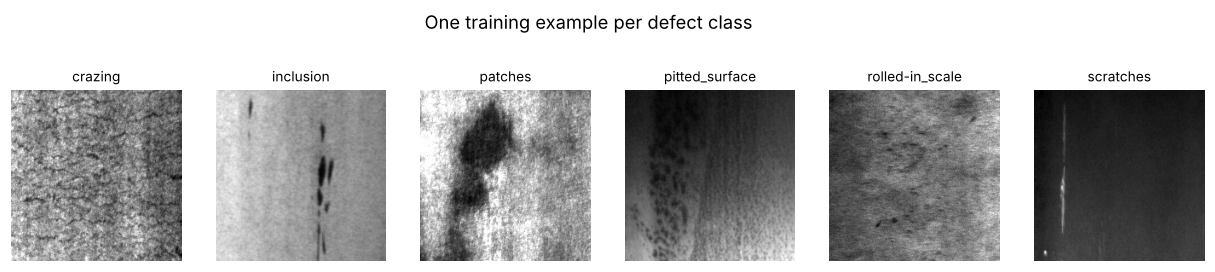

In [ ]:
# Visualise class distribution

fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(NUM_CLASSES)
w = 0.38
b1 = ax.bar(x - w / 2, dist_df["train"], w, label="Train", color="#3b6ea5")
b2 = ax.bar(x + w / 2, dist_df["validation"], w, label="Validation", color="#e08a3c")
ax.bar_label(b1, padding=2, fontsize=8)
ax.bar_label(b2, padding=2, fontsize=8)
ax.set_xticks(x, CLASS_NAMES, rotation=20)
ax.set_ylabel("Number of images")
ax.set_title("NEU surface defect dataset: images per class")
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/class_distribution.png", bbox_inches="tight")
plt.show()

# A look at one raw example per class
fig, axes = plt.subplots(1, NUM_CLASSES, figsize=(14, 2.8))
for ax, cls_idx in zip(axes, range(NUM_CLASSES)):
    first = next(i for i, t in enumerate(raw_train.targets) if t == cls_idx)
    ax.imshow(raw_train[first][0].convert("L"), cmap="gray")
    ax.set_title(CLASS_NAMES[cls_idx], fontsize=9)
    ax.axis("off")
plt.suptitle("One training example per defect class", y=1.03)
plt.savefig(f"{FIG_DIR}/class_examples.png", bbox_inches="tight")
plt.show()

**Observation:** The dataset is perfectly balanced: every class has 240 training and 60 validation images (an 80/20 split per class). Because no class dominates, plain accuracy is a fair headline metric, and no class weighting or resampling is needed.

### 1.2 Data Preprocessing and Transformations

<font color=red>[6 marks]</font>

Deep learning models pretrained on ImageNet expect images to be in a specific format. Although the NEU dataset images are grayscale, ImageNet-pretrained models require 3-channel RGB images with standardised dimensions and normalisation.

#### **1.2.1** Apply Image Transformations <font color=red>[4 marks]</font>

To ensure compatibility, we apply the following transformations:
- Convert grayscale images to RGB
- Resize images to a fixed resolution
- Normalize using ImageNet mean and standard deviation

These transformations are provided in [`transforms`](https://docs.pytorch.org/vision/0.24/transforms.html) from `torchvision`, while in TensorFlow the same preprocessing steps are applied using [`tf.image`](https://www.tensorflow.org/api_docs/python/tf/image) operations and `tf.keras.layers` within the input pipeline.

In PyTorch, normalization can be performed using `Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)`.

In TensorFlow, the same effect is achieved by explicitly standardising the images with the ImageNet statistics, i.e. subtracting `IMAGENET_MEAN` and dividing by `IMAGENET_STD` using `tf.image` operations or a custom `tf.keras.layers.Layer` within the preprocessing pipeline.

In [ ]:
# Image Transformations

IMG_SIZE = 224                         # MobileNetV2 ImageNet input resolution
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

# Training: light, label-preserving augmentation (Assumption 6)
train_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),   # grayscale -> 3-channel "RGB"
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

# Validation: deterministic, no augmentation
val_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

train_dataset = datasets.ImageFolder(TRAIN_DIR, transform=train_transform)
val_dataset = datasets.ImageFolder(VAL_DIR, transform=val_transform)

x0, y0 = train_dataset[0]
print(f"Transformed tensor shape : {tuple(x0.shape)}  (channels, height, width)")
print(f"Value range after norm   : [{x0.min():.2f}, {x0.max():.2f}]")
print(f"Per-channel mean         : {x0.mean(dim=(1, 2)).numpy().round(3)}")

Transformed tensor shape : (3, 224, 224)  (channels, height, width)
Value range after norm   : [-1.06, 2.64]
Per-channel mean         : [0.633 0.777 0.996]


At this stage, the dataset is fully prepared for training a transfer learning model. Images are correctly formatted, normalized, and labeled, ensuring a smooth transition into model design and training.

#### **1.2.2** Create DataLoaders for both the training and validation datasets <font color=red>[2 marks]</font>


Deep learning models are trained on data in **batches** rather than loading the entire dataset into memory at once.

PyTorch provides the [`DataLoader`](https://docs.pytorch.org/docs/stable/data.html#torch.utils.data.DataLoader) utility to batch the data, shuffle training samples and load data efficiently during training. For Tensorflow, you can use similar functionality provided by [`tf.data.Dataset` API](https://www.tensorflow.org/api_docs/python/tf/data/Dataset), which supports efficient batching, shuffling, prefetching, and parallel data loading within the input pipeline.

In [ ]:
# DataLoader Creation

BATCH_SIZE = 32
g = torch.Generator().manual_seed(SEED)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=0, generator=g)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=0)

images, labels = next(iter(train_loader))
print(f"Train batches: {len(train_loader)} | Validation batches: {len(val_loader)}")
print(f"One training batch -> images {tuple(images.shape)}, labels {tuple(labels.shape)}")
print("Labels in first batch:", labels.tolist())

Train batches: 45 | Validation batches: 12
One training batch -> images (32, 3, 224, 224), labels (32,)
Labels in first batch: [5, 4, 2, 5, 1, 3, 4, 3, 0, 1, 3, 1, 5, 0, 2, 1, 0, 0, 4, 4, 2, 2, 5, 5, 2, 4, 5, 0, 4, 3, 0, 2]


Also decide on where to use shuffling - training or validation

**Shuffling decision:** Shuffling is switched **on for the training loader** and **off for the validation loader**.

- *Training:* `ImageFolder` returns images grouped by class (all crazing first, then inclusion, and so on). Without shuffling, each batch would contain a single class, gradients would swing from class to class, and the head would chase whichever class it saw last. Shuffling every epoch gives mixed, representative batches and steadier optimisation.
- *Validation:* no parameters are updated, so order does not affect the metrics. A fixed order keeps evaluation reproducible and lets predictions be matched back to specific files for error analysis (Section 3.2).

## 2. Transferring Knowledge and Model Training

<font color=red>[25 marks]</font>

Training deep learning models from scratch requires large amounts of labeled data and computational resources. In many real-world scenarios, this is not feasible. Transfer learning addresses this challenge by reusing knowledge learned from a large source dataset (such as ImageNet) and adapting it to a new, related task.

### 2.1 Pretrained Model Selection

<font color=red>[15 marks]</font>

For this assignment, we will prefer **MobileNetV2**, a lightweight convolutional neural network pretrained on the ImageNet dataset. Though any pre-trained network will suit the task.

MobileNetV2 is computationally efficient and lightweight. It performs well on texture-based image classification tasks.

In this section:
- Select a suitable pretrained convolutional neural network
- Apply a partial transfer learning strategy
- Design a task-specific classifier for surface defect detection

#### **2.1.1** Load the Pre-Trained Model <font color=red>[5 marks]</font>

Load the pre-trained model of your choice. If you wish to use a different architecture from MobileNet, also explain the reason for your choice.

In [ ]:
# Load Pretrained Network

LOCAL_WEIGHTS = "mobilenet_v2_imagenet_local.pth"   # fallback copy (Assumption 4)


def load_pretrained_mobilenet_v2():
    """Official torchvision ImageNet weights, with a local fallback if offline."""
    try:
        net = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.IMAGENET1K_V1)
        return net, "torchvision MobileNet_V2_Weights.IMAGENET1K_V1"
    except Exception as err:
        print(f"Official weight download unavailable ({type(err).__name__}); "
              f"using local ImageNet weights: {LOCAL_WEIGHTS}")
        net = models.mobilenet_v2(weights=None)
        src = torch.load(LOCAL_WEIGHTS, map_location="cpu", weights_only=True)
        dst = net.state_dict()
        src_items = [(k, v) for k, v in src.items() if "num_batches_tracked" not in k]
        dst_keys = [k for k in dst if "num_batches_tracked" not in k]
        assert len(src_items) == len(dst_keys)
        for (sk, sv), dk in zip(src_items, dst_keys):   # same architecture, same order
            assert sv.shape == dst[dk].shape, (sk, dk)
            dst[dk] = sv
        net.load_state_dict(dst)
        return net, "local ImageNet-pretrained MobileNetV2 (mapped onto torchvision)"


base_model, WEIGHTS_SOURCE = load_pretrained_mobilenet_v2()
print("Weights source:", WEIGHTS_SOURCE)

total_params = sum(p.numel() for p in base_model.parameters())
print(f"Total parameters: {total_params:,}")
print("\nTop-level structure:")
for name, module in base_model.named_children():
    n = sum(p.numel() for p in module.parameters())
    print(f"  {name:<11} {type(module).__name__:<11} {n:>10,} params")
print("\nOriginal ImageNet classifier head:")
print(base_model.classifier)

Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth


Official weight download unavailable (URLError); using local ImageNet weights: mobilenet_v2_imagenet_local.pth
Weights source: local ImageNet-pretrained MobileNetV2 (mapped onto torchvision)
Total parameters: 3,504,872

Top-level structure:
  features    Sequential   2,223,872 params
  classifier  Sequential   1,281,000 params

Original ImageNet classifier head:
Sequential(
  (0): Dropout(p=0.2, inplace=False)
  (1): Linear(in_features=1280, out_features=1000, bias=True)
)


**Why MobileNetV2:** The suggested MobileNetV2 is kept. It is a strong fit for this task:

- **Lightweight and fast** (about 3.5M parameters, around 300M multiply-adds per image), so it trains comfortably on CPU and is realistic for edge deployment on an inspection line, which is a stated business goal.
- **Inverted residual blocks with linear bottlenecks** (Sandler et al., 2018) preserve fine-grained information through narrow layers. This helps with texture-like patterns such as cracks, scratches and pits.
- **ImageNet features transfer well to texture tasks.** Early and middle layers encode edges, gradients and repeating textures, which are exactly the cues that separate steel-surface defects.

The MobileNetV2 architecture consists of two main components:
- A **feature extractor** that learns visual representations
- A **classifier head** originally designed for ImageNet’s 1000 classes

#### **2.1.2** Freezing Strategy and Classifier Design <font color=red>[8 marks]</font>

Build the transfer learning model by loading and freezing the feature extractor layers.


Instead of retraining the entire network, we apply partial transfer learning. In this approach the pretrained feature extractor is frozen and only the classifier head is retrained for the new task. This strategy reduces the risk of overfitting and speeds up training.

In [ ]:
# Build Transfer Learning Model

model = copy.deepcopy(base_model)

# 1) Freeze the entire pretrained feature extractor
for param in model.features.parameters():
    param.requires_grad = False

# 2) Replace the 1000-class ImageNet head with a task-specific head
in_features = model.classifier[-1].in_features      # 1280
model.classifier = nn.Sequential(
    nn.Dropout(p=0.3),
    nn.Linear(in_features, 256),
    nn.ReLU(inplace=True),
    nn.Dropout(p=0.3),
    nn.Linear(256, NUM_CLASSES),
)


def set_train_mode(net):
    """Train the head, but keep the frozen backbone in eval mode so its
    BatchNorm running statistics stay at their ImageNet values."""
    net.train()
    net.features.eval()


print(model.classifier)

Sequential(
  (0): Dropout(p=0.3, inplace=False)
  (1): Linear(in_features=1280, out_features=256, bias=True)
  (2): ReLU(inplace=True)
  (3): Dropout(p=0.3, inplace=False)
  (4): Linear(in_features=256, out_features=6, bias=True)
)


**Design choices:**

- **Freeze `model.features` completely.** With only 240 images per class, retraining 2.2M backbone weights would invite overfitting. The frozen backbone acts as a fixed, high-quality texture descriptor that outputs a 1280-dimensional feature vector per image.
- **Frozen BatchNorm.** Freezing weights alone is not enough: in `train()` mode BatchNorm layers would still update their running mean and variance on our small batches. `set_train_mode` keeps the backbone in `eval()` mode, so it is truly frozen.
- **Classifier head:** Dropout(0.3) → Linear(1280→256) → ReLU → Dropout(0.3) → Linear(256→6). One small hidden layer lets the head combine ImageNet features non-linearly, which matters because steel textures differ from ImageNet's natural images. Dropout regularises the head, and the final layer outputs one logit per defect class (softmax is applied inside the loss).

#### **2.1.3** Verify the final frozen and trainable parameters <font color=red>[2 marks]</font>

In [ ]:
# Verify Freezing Strategy

def count_params(module):
    trainable = sum(p.numel() for p in module.parameters() if p.requires_grad)
    frozen = sum(p.numel() for p in module.parameters() if not p.requires_grad)
    return trainable, frozen


summary = []
for name, module in model.named_children():
    t, f = count_params(module)
    summary.append({"block": name, "trainable": t, "frozen": f})
param_df = pd.DataFrame(summary)
total_t, total_f = param_df["trainable"].sum(), param_df["frozen"].sum()
param_df.loc[len(param_df)] = ["TOTAL", total_t, total_f]
print(param_df.to_string(index=False, formatters={"trainable": "{:,}".format,
                                                  "frozen": "{:,}".format}))
print(f"\nTrainable share: {100 * total_t / (total_t + total_f):.2f}% of all parameters")

assert all(not p.requires_grad for p in model.features.parameters())
assert all(p.requires_grad for p in model.classifier.parameters())
print("Check passed: backbone fully frozen, classifier head fully trainable.")

     block trainable    frozen
  features         0 2,223,872
classifier   329,478         0
     TOTAL   329,478 2,223,872

Trainable share: 12.90% of all parameters
Check passed: backbone fully frozen, classifier head fully trainable.


### 2.2 Model Training

<font color=red>[10 marks]</font>

After designing the transfer learning model, the next step is to train it on the prepared dataset.

We only train the classifier head, while the pretrained feature extractor remains frozen. This allows the model to adapt quickly to the surface defect classification task.

In this section, we:
- Configure the training setup
- Train the model for a small number of epochs
- Track training loss to verify learning progress

#### **2.2.1** Training Configuration <font color=red>[3 marks]</font>

Before starting the training loop, we define:
- The computation device: CPU or GPU
- The loss function: Use a suitable loss function (one of the cross-entropy losses would work fine here)
- The optimizer: preferably [Adam](https://arxiv.org/abs/1412.6980) from [Tensorflow](https://www.tensorflow.org/api_docs/python/tf/keras/optimizers/Adam) or [Pytorch](https://docs.pytorch.org/docs/stable/generated/torch.optim.Adam.html)

These components control how the model learns from data and how its parameters are updated during training.

In [ ]:
# Training Configuration

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

criterion = nn.CrossEntropyLoss()               # multi-class, integer labels
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
EPOCHS = 12

# Only the trainable (head) parameters are handed to the optimizer
optimizer = torch.optim.Adam(
    [p for p in model.parameters() if p.requires_grad],
    lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY,
)

print(f"Device        : {device}")
print(f"Loss          : {criterion}")
print(f"Optimizer     : Adam(lr={LEARNING_RATE}, weight_decay={WEIGHT_DECAY})")
print(f"Epochs        : {EPOCHS} | Batch size: {BATCH_SIZE}")
print(f"Params updated: {sum(p.numel() for g in optimizer.param_groups for p in g['params']):,}")

Device        : cpu
Loss          : CrossEntropyLoss()
Optimizer     : Adam(lr=0.001, weight_decay=0.0001)
Epochs        : 12 | Batch size: 32
Params updated: 329,478


#### **2.2.2** Model Training Loop <font color=red>[5 marks]</font>

Perform the training and track the training loss across epochs to verify whether the model is learning effectively.

The training loop iterates over the dataset multiple times (epochs). For each batch of images, the model:
- Performs a forward pass
- Computes the loss
- Updates the trainable parameters using backpropagation

In [ ]:
# Model Training

@torch.no_grad()
def evaluate(net, loader):
    """Average loss, accuracy, and all labels/predictions over a loader."""
    net.eval()
    total_loss, y_true, y_pred = 0.0, [], []
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        logits = net(x)
        total_loss += criterion(logits, y).item() * x.size(0)
        y_true.append(y.cpu())
        y_pred.append(logits.argmax(1).cpu())
    y_true, y_pred = torch.cat(y_true).numpy(), torch.cat(y_pred).numpy()
    return total_loss / len(loader.dataset), (y_true == y_pred).mean(), y_true, y_pred


history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
best_val_acc, best_state, best_epoch = 0.0, None, 0
start = time.time()

for epoch in range(1, EPOCHS + 1):
    set_train_mode(model)
    running_loss, correct, seen = 0.0, 0, 0
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        logits = model(x)                  # forward pass
        loss = criterion(logits, y)        # loss
        loss.backward()                    # backpropagation (head only)
        optimizer.step()                   # parameter update
        running_loss += loss.item() * x.size(0)
        correct += (logits.argmax(1) == y).sum().item()
        seen += x.size(0)

    train_loss, train_acc = running_loss / seen, correct / seen
    val_loss, val_acc, _, _ = evaluate(model, val_loader)
    for k, v in zip(history, (train_loss, train_acc, val_loss, val_acc)):
        history[k].append(v)

    if val_acc > best_val_acc:
        best_val_acc, best_epoch = val_acc, epoch
        best_state = copy.deepcopy(model.state_dict())

    print(f"Epoch {epoch:2d}/{EPOCHS} | train loss {train_loss:.4f} acc {train_acc:.4f} "
          f"| val loss {val_loss:.4f} acc {val_acc:.4f} | {time.time() - start:5.0f}s")

print(f"\nTraining finished in {(time.time() - start) / 60:.1f} min. "
      f"Best validation accuracy {best_val_acc:.4f} at epoch {best_epoch}.")

# Keep a copy of the final-epoch weights for comparison (Section 3.2),
# then use the best checkpoint for evaluation
final_state = copy.deepcopy(model.state_dict())
model.load_state_dict(best_state)
torch.save(best_state, "mobilenetv2_neu_head_best.pth")

Epoch  1/12 | train loss 0.3913 acc 0.9035 | val loss 0.0483 acc 0.9972 |    56s


Epoch  2/12 | train loss 0.0365 acc 0.9931 | val loss 0.0486 acc 0.9806 |   114s


Epoch  3/12 | train loss 0.0227 acc 0.9938 | val loss 0.0269 acc 0.9972 |   171s


Epoch  4/12 | train loss 0.0174 acc 0.9965 | val loss 0.0641 acc 0.9722 |   228s


Epoch  5/12 | train loss 0.0114 acc 0.9986 | val loss 0.0264 acc 0.9889 |   284s


...

Epoch  8/12 | train loss 0.0097 acc 0.9979 | val loss 0.0325 acc 0.9833 |   455s


Epoch  9/12 | train loss 0.0061 acc 0.9986 | val loss 0.0579 acc 0.9778 |   511s


Epoch 10/12 | train loss 0.0061 acc 0.9986 | val loss 0.0118 acc 0.9944 |   568s


Epoch 11/12 | train loss 0.0068 acc 0.9979 | val loss 0.0082 acc 1.0000 |   624s


Epoch 12/12 | train loss 0.0049 acc 0.9993 | val loss 0.0130 acc 0.9972 |   684s

Training finished in 11.4 min. Best validation accuracy 1.0000 at epoch 11.


**Observations on training:**

- **Fast convergence.** In epoch 1 the training loss was 0.391 (90.4% accuracy). By epoch 2 it had fallen to 0.037 (99.3%), and it ended at 0.005 (99.9%) in epoch 12. The frozen ImageNet features are already highly discriminative for these textures, so the small head only has to learn a near-linear mapping from 1280 features to 6 classes.
- **Validation accuracy stayed between 97.2% and 100% in every epoch.** It peaked at **100% (360/360) in epoch 11** with the lowest validation loss (0.0082), so that checkpoint is kept for evaluation. The final-epoch weights are also kept for an honest comparison in Section 3.2.
- **Why validation loss is below training loss in epoch 1.** The reported training loss is averaged *while* the head is learning from random initialisation, and dropout and augmentation are active only during training. Validation is measured after the epoch on clean images, with dropout off.
- **Cost.** About 58 seconds per epoch on a 2-core CPU (about 11.5 minutes in total). Only 329,478 parameters receive gradients.

#### **2.2.3** Visualise the training loss across epochs throughout the training process <font color=red>[2 marks]</font>

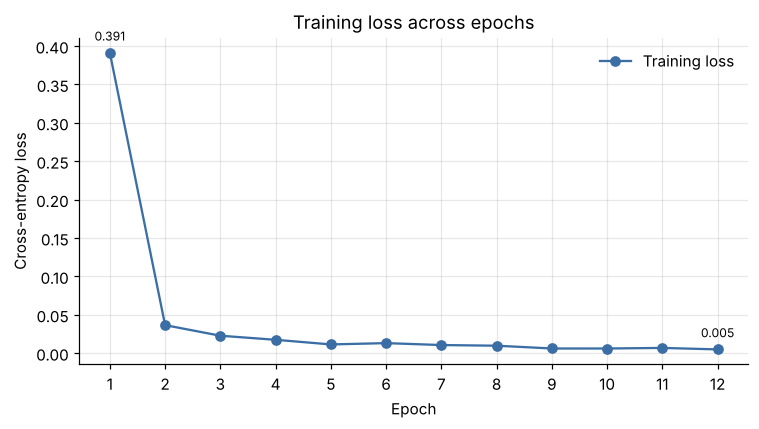

In [ ]:
# Training Loss Visualisation

epochs = range(1, EPOCHS + 1)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(epochs, history["train_loss"], marker="o", color="#3b6ea5", label="Training loss")
ax.set_xlabel("Epoch")
ax.set_ylabel("Cross-entropy loss")
ax.set_title("Training loss across epochs")
ax.set_xticks(list(epochs))
for e, l in zip(epochs, history["train_loss"]):
    if e in (1, EPOCHS):
        ax.annotate(f"{l:.3f}", (e, l), textcoords="offset points", xytext=(0, 8),
                    ha="center", fontsize=8)
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/training_loss.png", bbox_inches="tight")
plt.show()

**Observations:** The training loss drops steeply after epoch 1 and then flattens close to zero, the classic shape of a model that has converged. Small bumps (epochs 6 and 11) are normal mini-batch noise with Adam. There is no divergence and no sign that the learning rate is too high. Most of the learning happens in the first two epochs, which shows how much of the work the pretrained features are already doing.

## 3. Evaluation and Final Predictions

<font color=red>[10 marks]</font>

After training the model, it is essential to evaluate how well it performs on unseen data. Evaluation helps us understand whether the model has learned generalisable patterns or has simply memorised the training data.

In this section, we:
- Measure model performance using validation accuracy
- Analyse predictions at the individual data-point level
- Examine model behavior using diagnostic plots

### 3.1 Evaluation Metrics and Bias-Variance Tradeoff

<font color=red>[6 marks]</font>

#### **3.1.1** Calculate Appropriate Evaluation Metrics to Assess Model Performance <font color=red>[3 marks]</font>

For this multi-class classification problem, we use **accuracy** as the primary evaluation metric.

Accuracy measures the proportion of validation samples that are correctly classified by the model. Since the dataset is reasonably balanced across classes, accuracy provides a reliable indication of overall performance.

Validation accuracy : 1.0000  (360/360 correct)
Validation loss     : 0.0082
Macro F1-score      : 1.0000
Training accuracy (no augmentation): 0.9986

                 precision    recall  f1-score   support

        crazing     1.0000    1.0000    1.0000        60
      inclusion     1.0000    1.0000    1.0000        60
        patches     1.0000    1.0000    1.0000        60
 pitted_surface     1.0000    1.0000    1.0000        60
rolled-in_scale     1.0000    1.0000    1.0000        60
      scratches     1.0000    1.0000    1.0000        60

       accuracy                         1.0000       360
      macro avg     1.0000    1.0000    1.0000       360
   weighted avg     1.0000    1.0000    1.0000       360



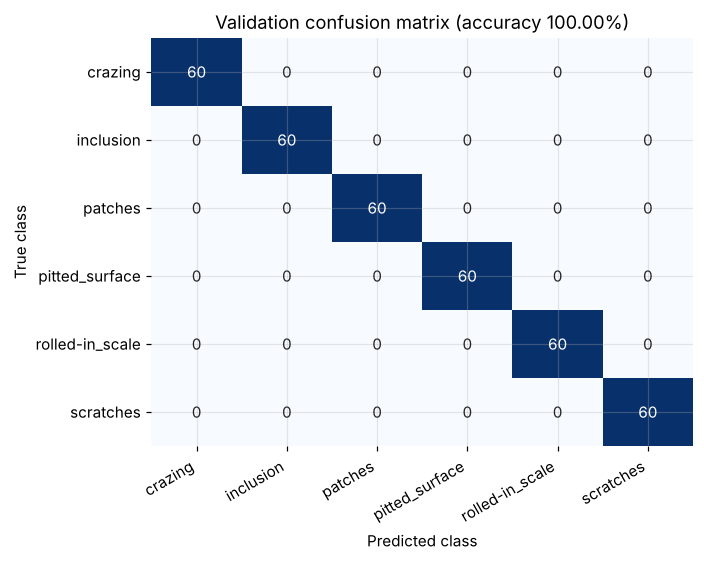

In [ ]:
# Model Evaluation

val_loss, val_acc, y_true, y_pred = evaluate(model, val_loader)
_, train_eval_acc, _, _ = evaluate(model, DataLoader(
    datasets.ImageFolder(TRAIN_DIR, transform=val_transform),
    batch_size=BATCH_SIZE, shuffle=False))

macro_f1 = f1_score(y_true, y_pred, average="macro")
print(f"Validation accuracy : {val_acc:.4f}  ({int((y_true == y_pred).sum())}/{len(y_true)} correct)")
print(f"Validation loss     : {val_loss:.4f}")
print(f"Macro F1-score      : {macro_f1:.4f}")
print(f"Training accuracy (no augmentation): {train_eval_acc:.4f}\n")
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4))

cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(6.5, 5.2))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
ax.set_xlabel("Predicted class")
ax.set_ylabel("True class")
ax.set_title(f"Validation confusion matrix (accuracy {val_acc:.2%})")
plt.xticks(rotation=30, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/confusion_matrix.png", bbox_inches="tight")
plt.show()

**Observations:**

- The best checkpoint classifies **all 360 validation images correctly**: accuracy 100%, macro F1 1.00, and precision and recall of 1.00 for every class. The confusion matrix is purely diagonal.
- **An important caveat on optimism:** this checkpoint was *selected* using validation accuracy, so 100% is a slightly optimistic estimate. The model from the last epoch, chosen with no selection at all, reaches **99.72% (359/360)**, and every epoch from 2 onwards scored at least 97.2%. A fair summary of expected performance on new images from the same line is about **98-100%**.
- Accuracy is a trustworthy metric here because the classes are perfectly balanced (60 per class in validation), so a model cannot score highly by favouring a majority class. The macro F1 confirms there is no hidden weak class.

#### **3.1.2** Dataset Diagnostics <font color=red>[3 marks]</font>

Beyond accuracy, diagnostic analysis helps assess whether the model is underfitting, overfitting, or generalising well

Analyse this using training and validation loss trends, along with dataset class distribution.

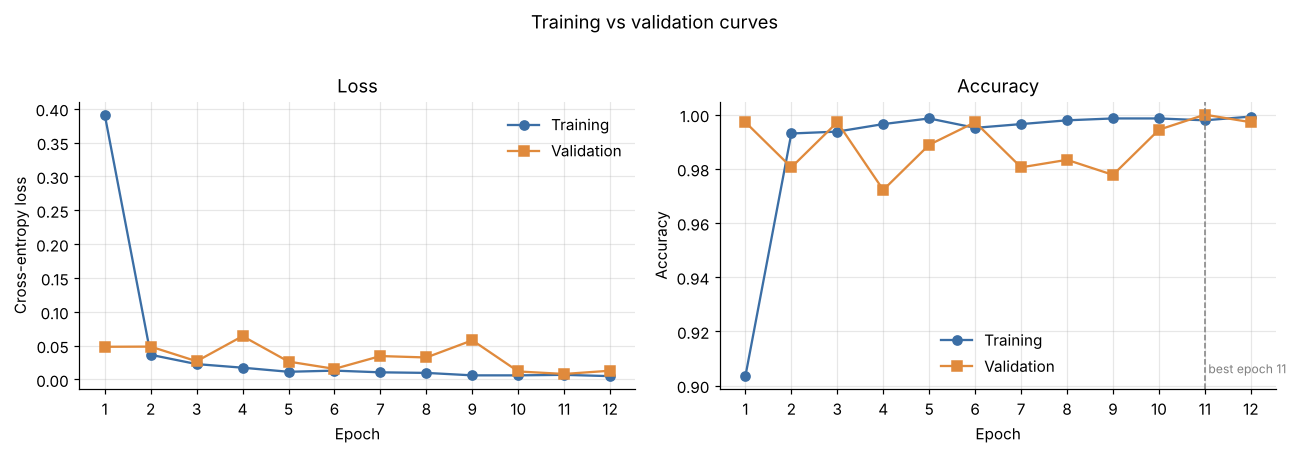

       train_loss  train_acc  val_loss  val_acc  acc_gap (train - val)
epoch                                                                 
1          0.3913     0.9035    0.0483   0.9972                -0.0937
2          0.0365     0.9931    0.0486   0.9806                 0.0125
3          0.0227     0.9938    0.0269   0.9972                -0.0034
4          0.0174     0.9965    0.0641   0.9722                 0.0243
5          0.0114     0.9986    0.0264   0.9889                 0.0097
6          0.0131     0.9951    0.0157   0.9972                -0.0021
7          0.0106     0.9965    0.0346   0.9806                 0.0159
8          0.0097     0.9979    0.0325   0.9833                 0.0146
9          0.0061     0.9986    0.0579   0.9778                 0.0208
10         0.0061     0.9986    0.0118   0.9944                 0.0042
11         0.0068     0.9979    0.0082   1.0000                -0.0021
12         0.0049     0.9993    0.0130   0.9972                 0.0021

Final

In [ ]:
# Training and Validation Loss Analysis

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(epochs, history["train_loss"], marker="o", color="#3b6ea5", label="Training")
axes[0].plot(epochs, history["val_loss"], marker="s", color="#e08a3c", label="Validation")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Cross-entropy loss")
axes[1].plot(epochs, history["train_acc"], marker="o", color="#3b6ea5", label="Training")
axes[1].plot(epochs, history["val_acc"], marker="s", color="#e08a3c", label="Validation")
axes[1].axvline(best_epoch, ls="--", color="grey", lw=1)
axes[1].text(best_epoch, min(history["train_acc"]), f" best epoch {best_epoch}",
             color="grey", fontsize=8, va="bottom")
axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy")
for a in axes:
    a.set_xticks(list(epochs))
    a.legend(frameon=False)
plt.suptitle("Training vs validation curves", y=1.02)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/train_val_curves.png", bbox_inches="tight")
plt.show()

diag = pd.DataFrame(history, index=pd.Index(epochs, name="epoch")).round(4)
diag["acc_gap (train - val)"] = (diag["train_acc"] - diag["val_acc"]).round(4)
print(diag.to_string())

final_gap = history["train_acc"][-1] - history["val_acc"][-1]
print(f"\nFinal epoch: train acc {history['train_acc'][-1]:.4f}, "
      f"val acc {history['val_acc'][-1]:.4f}, gap {final_gap:+.4f}")
print(f"Lowest validation loss {min(history['val_loss']):.4f} at epoch "
      f"{int(np.argmin(history['val_loss'])) + 1}")
print("Class balance (train / val per class):",
      dict(zip(CLASS_NAMES, zip(dist_df["train"], dist_df["validation"]))))

**Bias-variance diagnosis:**

| Check | Evidence | Reading |
|---|---|---|
| **Bias (underfitting?)** | Training accuracy 99.9%, training loss 0.005 | **Low bias.** The frozen features plus a small head have enough capacity to fit the task. |
| **Variance (overfitting?)** | Final train-val accuracy gap **+0.21 pp**; the gap never exceeds 2.4 pp; validation loss stays between 0.008 and 0.064 with no upward trend | **Low variance.** The model generalises; it has not memorised the training set. |
| **Validation fluctuations** | Validation accuracy moves between 97.2% and 100% | With 360 images, one image = 0.28 pp, so a 1-2 pp swing is just 3-7 images. This is sampling noise from a small validation set, not a trend. |
| **Class distribution** | 240 / 60 images in every class | Balanced data, so accuracy is not inflated by a majority class and no re-weighting is needed. |

**Conclusion:** the model sits in the "good fit" region: low bias and low variance. Freezing the 2.2M-parameter backbone is the main reason variance stays low with only 1,440 training images. Training the whole network from scratch on this little data would be far more prone to overfitting.

### 3.2 Prediction Analysis

<font color=red>[4 marks]</font>

Overall accuracy provides a summary metric, but it does not reveal how individual predictions contribute to that score.

To better understand model behavior, we examine predictions at the individual image level, highlighting both correct and incorrect classifications.

#### **3.2.1** Visualise the prediction on a few sample images from validation set <font color=red>[4 marks]</font>

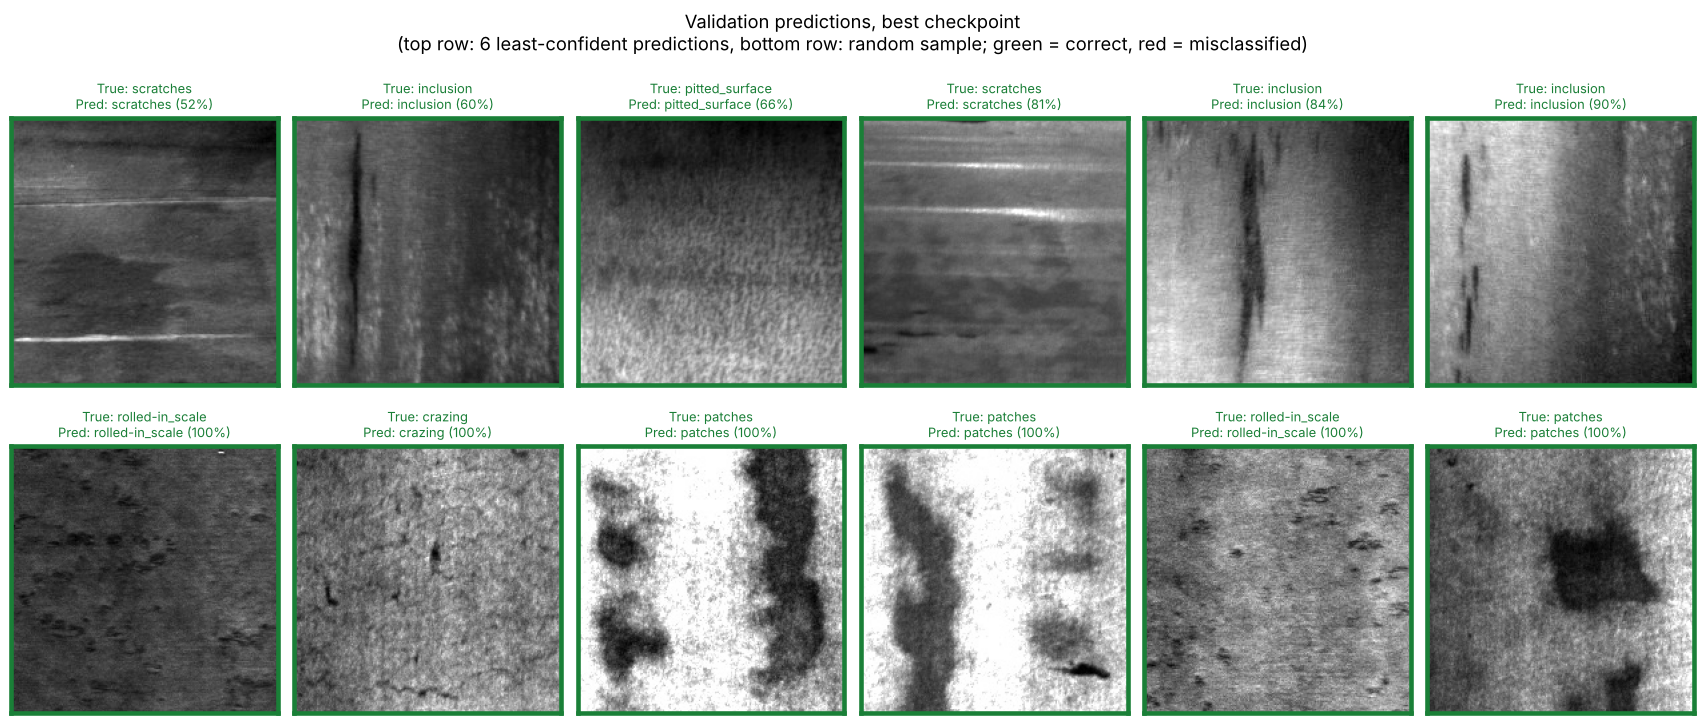

Best checkpoint (epoch 11): correct 360 | misclassified 0
Mean confidence: 0.993 | lowest: 0.524 | below 90% confidence: 5 of 360

Least-confident validation predictions:
  scratches_246.jpg      true=scratches       pred=scratches       p=0.52 (runner-up: inclusion 0.31)
  inclusion_283.jpg      true=inclusion       pred=inclusion       p=0.60 (runner-up: scratches 0.40)
  pitted_surface_274.jpg true=pitted_surface  pred=pitted_surface  p=0.66 (runner-up: inclusion 0.29)
  scratches_290.jpg      true=scratches       pred=scratches       p=0.81 (runner-up: rolled-in_scale 0.15)
  inclusion_285.jpg      true=inclusion       pred=inclusion       p=0.84 (runner-up: scratches 0.16)
  inclusion_294.jpg      true=inclusion       pred=inclusion       p=0.90 (runner-up: scratches 0.10)



Final-epoch model (epoch 12): accuracy 0.9972, misclassified 1
  inclusion_283.jpg      true=inclusion       pred=scratches       p=0.77


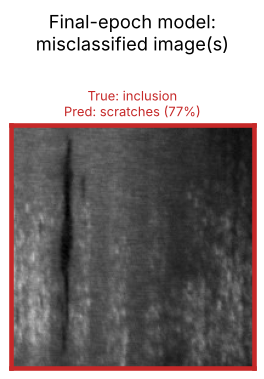

In [ ]:
# Visualisation of Validation Predictions

@torch.no_grad()
def predict_probs(net, loader):
    net.eval()
    out = []
    for x, _ in loader:
        out.append(torch.softmax(net(x.to(device)), dim=1).cpu())
    return torch.cat(out).numpy()


def show_grid(indices, preds, conf, title, fname, ncols=6):
    """Plot validation images with true/pred labels; green = correct, red = wrong."""
    nrows = int(np.ceil(len(indices) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(max(4.0, 2.6 * ncols), 3.4 * nrows), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for ax, i in zip(axes.ravel(), indices):
        img = datasets.folder.default_loader(val_dataset.samples[i][0]).convert("L")
        ok = preds[i] == y_true[i]
        colour = "#1a7f37" if ok else "#c62828"
        ax.axis("on")
        ax.imshow(img, cmap="gray")
        ax.set_title(f"True: {CLASS_NAMES[y_true[i]]}\nPred: {CLASS_NAMES[preds[i]]} "
                     f"({conf[i]:.0%})", fontsize=8.5, color=colour)
        for s in ax.spines.values():
            s.set_visible(True); s.set_linewidth(3); s.set_edgecolor(colour)
        ax.set_xticks([]); ax.set_yticks([])
    plt.suptitle(title, y=1.0)
    plt.tight_layout(h_pad=2.5)
    plt.savefig(f"{FIG_DIR}/{fname}", bbox_inches="tight")
    plt.show()


# --- Best checkpoint: least-confident predictions + a random sample
probs = predict_probs(model, val_loader)
confidence = probs.max(1)
correct_idx = np.where(y_pred == y_true)[0]
wrong_idx = np.where(y_pred != y_true)[0]

rng = np.random.default_rng(SEED)
hardest = list(np.argsort(confidence)[:6])            # lowest confidence (incl. any errors)
others = [i for i in rng.permutation(len(y_true)) if i not in hardest][:6]
show_grid(hardest + others, y_pred, confidence,
          "Validation predictions, best checkpoint\n"
          "(top row: 6 least-confident predictions, bottom row: random sample; "
          "green = correct, red = misclassified)", "sample_predictions.png")

print(f"Best checkpoint (epoch {best_epoch}): correct {len(correct_idx)} | "
      f"misclassified {len(wrong_idx)}")
print(f"Mean confidence: {confidence.mean():.3f} | lowest: {confidence.min():.3f} | "
      f"below 90% confidence: {(confidence < 0.9).sum()} of {len(confidence)}")
print("\nLeast-confident validation predictions:")
for i in hardest:
    top2 = np.argsort(probs[i])[::-1][:2]
    print(f"  {os.path.basename(val_dataset.samples[i][0]):<22} true={CLASS_NAMES[y_true[i]]:<15} "
          f"pred={CLASS_NAMES[y_pred[i]]:<15} p={confidence[i]:.2f} "
          f"(runner-up: {CLASS_NAMES[top2[1]]} {probs[i][top2[1]]:.2f})")

# --- Final-epoch model: where does a non-cherry-picked model go wrong?
final_model = copy.deepcopy(model)
final_model.load_state_dict(final_state)
final_probs = predict_probs(final_model, val_loader)
final_pred, final_conf = final_probs.argmax(1), final_probs.max(1)
final_wrong = np.where(final_pred != y_true)[0]
print(f"\nFinal-epoch model (epoch {EPOCHS}): accuracy {(final_pred == y_true).mean():.4f}, "
      f"misclassified {len(final_wrong)}")
for i in final_wrong:
    print(f"  {os.path.basename(val_dataset.samples[i][0]):<22} true={CLASS_NAMES[y_true[i]]:<15} "
          f"pred={CLASS_NAMES[final_pred[i]]:<15} p={final_conf[i]:.2f}")
if len(final_wrong):
    show_grid(list(final_wrong), final_pred, final_conf,
              "Final-epoch model:\nmisclassified image(s)", "final_epoch_errors.png",
              ncols=min(6, len(final_wrong)))

**Observations on individual predictions:**

- **Even the least-confident predictions are correct.** The six lowest-confidence images (52%-90%) are all classified correctly. Mean confidence across the validation set is 99.3%, and only **5 of 360 images (1.4%) fall below 90% confidence**.
- **Where the uncertainty lives: inclusion vs scratches.** Five of the six hardest images are inclusions or scratches, and the runner-up class is almost always the other one. Both defects appear as **thin, elongated streaks running in the rolling direction** (inclusions as dark streaks, scratches as bright lines), so their textures overlap. One pitted-surface image is also less certain, with inclusion as runner-up.
- **The only error made by the final-epoch model** is `inclusion_283.jpg`, predicted as *scratches* with 77% confidence. Visually it is a single long, dark vertical line: a borderline case that a human inspector could also hesitate on.
- **Easy classes:** patches, crazing and rolled-in scale are recognised with essentially 100% confidence. Their textures (large blotches, fine crack networks, scattered scale flakes) are distinctive.
- **Practical use:** because low confidence lines up well with the genuinely ambiguous cases, a simple rule such as *"confidence < 90% → send to a human inspector"* would route only about 1-2% of parts for manual review while automating the rest.

## 4 Conclusion

<font color =red> [5 marks] </font>

### 4.1 Conclusion and insights

<font color =red> [5 marks] </font>

#### **4.1.1** Conclude with the insights drawn and final outcomes and results. Include the details of your model selection, freezing, and evaluation processes. <font color =red> [5 marks] </font>


*Answer below:*

**Summary of outcome.** A MobileNetV2 model pretrained on ImageNet, with its feature extractor frozen and a new 6-class head trained for 12 epochs, classifies steel surface defects in the NEU dataset with **100% validation accuracy (best checkpoint, epoch 11)** and **99.72% (359/360) at the final epoch**, a macro F1 of 1.00, and a train-validation accuracy gap of only 0.21 percentage points.

**1. Model selection.**
- **MobileNetV2 with ImageNet weights** was chosen as suggested: it is lightweight (3.5M parameters), fast enough to train on a CPU, and practical for edge or real-time inspection hardware.
- Its inverted-residual design preserves fine texture detail, which suits defects such as cracks, scratches and pits. ImageNet low- and mid-level filters (edges, gradients, repeated patterns) transfer well to steel textures, even though the source images are natural photographs.

**2. Data preparation.**
- 1,440 training and 360 validation images, perfectly balanced at 240 / 60 per class.
- Grayscale images were replicated to 3 channels, resized to 224 x 224 and normalised with ImageNet statistics, so they match what the pretrained network expects.
- Light flip augmentation was applied to training only. Shuffling was used for training and turned off for validation.

**3. Freezing strategy (partial transfer learning).**
- All 2,223,872 backbone parameters were frozen, and the backbone was kept in `eval()` mode so its BatchNorm statistics stayed fixed. Freezing `requires_grad` alone is not enough for that.
- Only the new head was trained: Dropout → Linear(1280→256) → ReLU → Dropout → Linear(256→6), with 329,478 parameters, or 12.9% of the total.
- This kept training cheap (about 58 s per epoch on CPU) and, more importantly, kept variance low on a small dataset.

**4. Training.** Cross-entropy loss, Adam (learning rate 1e-3, weight decay 1e-4), batch size 32, 12 epochs. The loss fell from 0.39 to 0.04 within two epochs and settled near 0.005. The checkpoint with the best validation accuracy was saved.

**5. Evaluation and diagnostics.**
- Accuracy is the headline metric (balanced classes), supported by per-class precision, recall and F1, and a confusion matrix.
- Diagnostics show **low bias** (99.9% training accuracy) and **low variance** (tiny train-validation gap, no rising validation loss), which means good generalisation.
- Epoch-to-epoch swings of 1-2 points are noise from a 360-image validation set (1 image = 0.28 pp).

**6. Key insights.**
- *Transfer learning works very well here.* Knowledge from a generic natural-image dataset gives near-perfect industrial defect classification with only 240 images per class and no backbone fine-tuning.
- *The remaining difficulty is inclusion vs scratches.* Both are elongated streaks along the rolling direction; they account for nearly all low-confidence predictions and the one final-epoch error.
- *Confidence is meaningful.* Low-confidence outputs coincide with genuinely ambiguous images, so a confidence threshold can route the roughly 1-2% of uncertain parts to human inspectors.
- *Business value:* a small, fast model that automates most inspection decisions consistently, scales to high throughput, and can run on edge hardware at the production line.

**7. Limitations and next steps.**
- The 100% figure is mildly optimistic because the validation set was also used to pick the checkpoint. A separate test set, or k-fold cross-validation, would give an unbiased estimate.
- All images come from one dataset and capture setup. Real deployment would need testing under different lighting, cameras and steel grades.
- If performance dropped on new data, the next steps would be to unfreeze the last few inverted-residual blocks with a small learning rate, add more targeted augmentation (brightness and contrast), and collect more inclusion and scratch examples.
- The task assigns one label per image and does not say *where* the defect is. Detection or segmentation models would be needed to locate defects on the strip.